In [ ]:
import pandas as pd
import numpy as np
import scipy.stats
import seaborn as sns
import matplotlib.pyplot as plt
import pingouin as pg
import sklearn as sk

pd.set_option("display.max_rows", None)      # show every row - dataset is small enough to inspect in full
pd.set_option("display.max_colwidth", None)  # never truncate cell text - need to read full src/mt strings

FILE_PATH = "divemt_cometkiwi_qe.csv"

### Create the Google and Mbart50 dataset

DivEMT uses 2 machine translation engine to populate machine translated text.
To prepare for the experiment, 2 datasets are created from divEMT:
1. google : only contains data around machine translation populated by Google Translated
2. mbart50: only contains data around machine translation populated by MBART50

In [141]:
df_qe = pd.read_csv(FILE_PATH)
google = df_qe[df_qe['task_type'] == 'pe1']
mbart50 = df_qe[df_qe['task_type'] == 'pe2']
google.shape, mbart50.shape

((2580, 65), (2580, 65))

# PIPELINE TEST USING GOOGLE DATASET ONLY

### 1. Check correlation between QE score and source length

Kendal correlation shows that QE score and source length have very weak relationship, but if one goes up, the other goes down. It makes sense, because A longer source text tends to have lower QE score, and a shorter text might have higher QE score

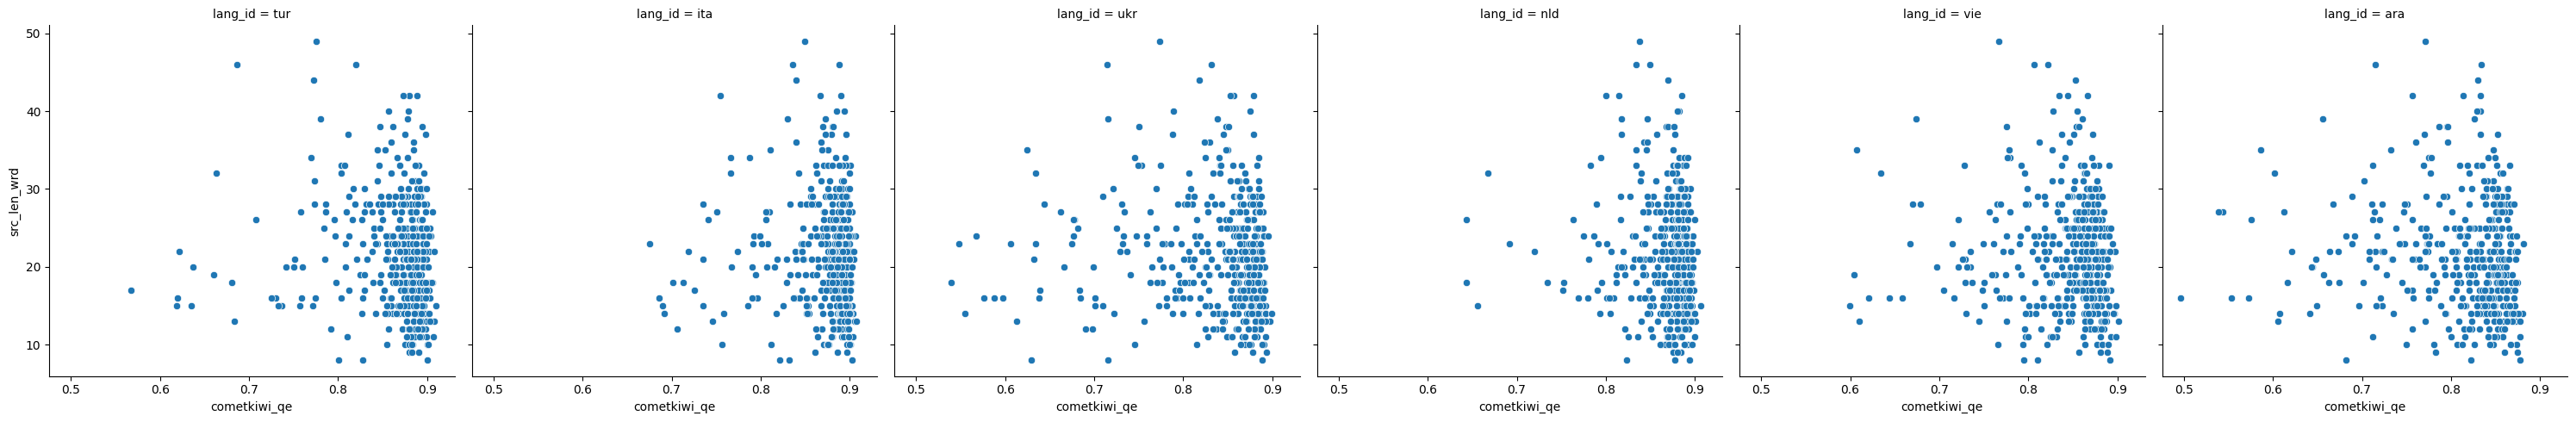

In [66]:
plot_google = sns.relplot(data=google, y='src_len_wrd', x='cometkiwi_qe', col='lang_id')


In [144]:
print("Spearman correlation between QE score of Google translate and source length (words):")
(google.groupby(['lang_id'])
      .apply(lambda g: g.cometkiwi_qe.corr(g.src_len_wrd, method='spearman')))


Spearman correlation between QE score of Google translate and source length (words):


/var/folders/dl/4ftjqphn6jl0c7zhmph3khc00000gn/T/ipykernel_38586/3965750262.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.cometkiwi_qe.corr(g.src_len_wrd, method='spearman')))


lang_id
ara   -0.159630
ita   -0.121495
nld   -0.121170
tur   -0.194406
ukr   -0.165805
vie   -0.125698
dtype: float64

### Prediction for google translate

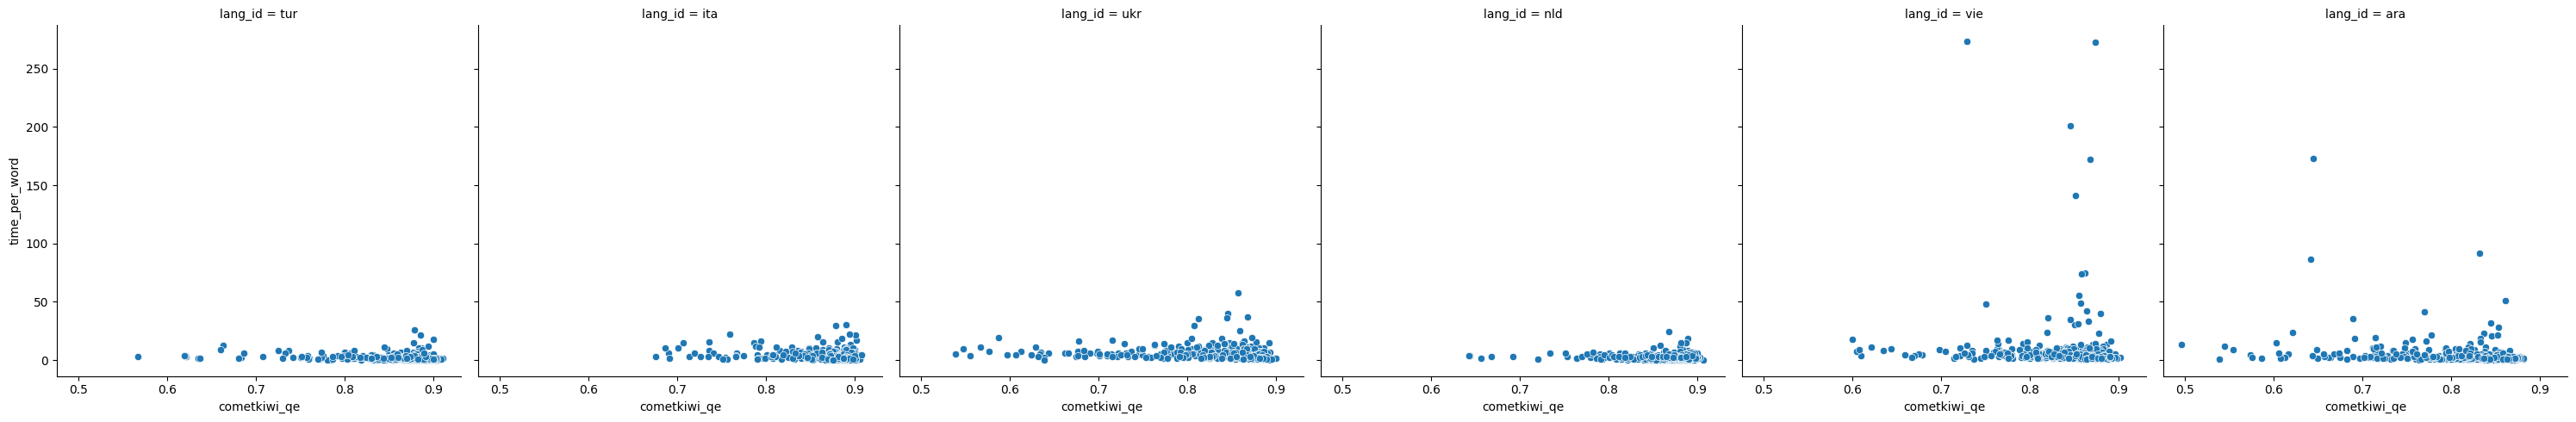

In [90]:
plot_qe_pe_google = sns.relplot(data=google,  x='cometkiwi_qe',y='time_per_word', col='lang_id')


In [93]:
(google.groupby(['lang_id'])
      .apply(lambda g: g.cometkiwi_qe.corr(g.time_per_word, method='spearman')))

/var/folders/dl/4ftjqphn6jl0c7zhmph3khc00000gn/T/ipykernel_38586/2127761706.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.cometkiwi_qe.corr(g.time_per_word, method='spearman')))


lang_id
ara   -0.369702
ita   -0.271438
nld   -0.123306
tur   -0.265870
ukr   -0.318557
vie   -0.315458
dtype: float64

In [112]:
import pingouin as pg
for i in google['lang_id'].unique():
    lang = google[google['lang_id'] == i]
    result=pg.partial_corr(data=lang, x='cometkiwi_qe', y='edit_time',
                    covar='src_len_wrd', method='spearman')
    print(f"Partial correlation for {i}:\n" + str(result))



Partial correlation for tur:
            n         r            CI95         p_val
spearman  430 -0.255257  [-0.34, -0.16]  8.294475e-08
Partial correlation for ita:
            n         r            CI95         p_val
spearman  430 -0.264369  [-0.35, -0.17]  2.714572e-08
Partial correlation for ukr:
            n         r            CI95         p_val
spearman  430 -0.304522  [-0.39, -0.22]  1.174390e-10
Partial correlation for nld:
            n        r            CI95     p_val
spearman  430 -0.13178  [-0.22, -0.04]  0.006268
Partial correlation for vie:
            n         r            CI95         p_val
spearman  430 -0.305189  [-0.39, -0.22]  1.064979e-10
Partial correlation for ara:
            n         r            CI95         p_val
spearman  430 -0.377533  [-0.46, -0.29]  5.568575e-16


In [ ]:
google['edit_time'].agg(['min', 'median', 'max'])
(google['edit_time'] <= 0).sum()


0

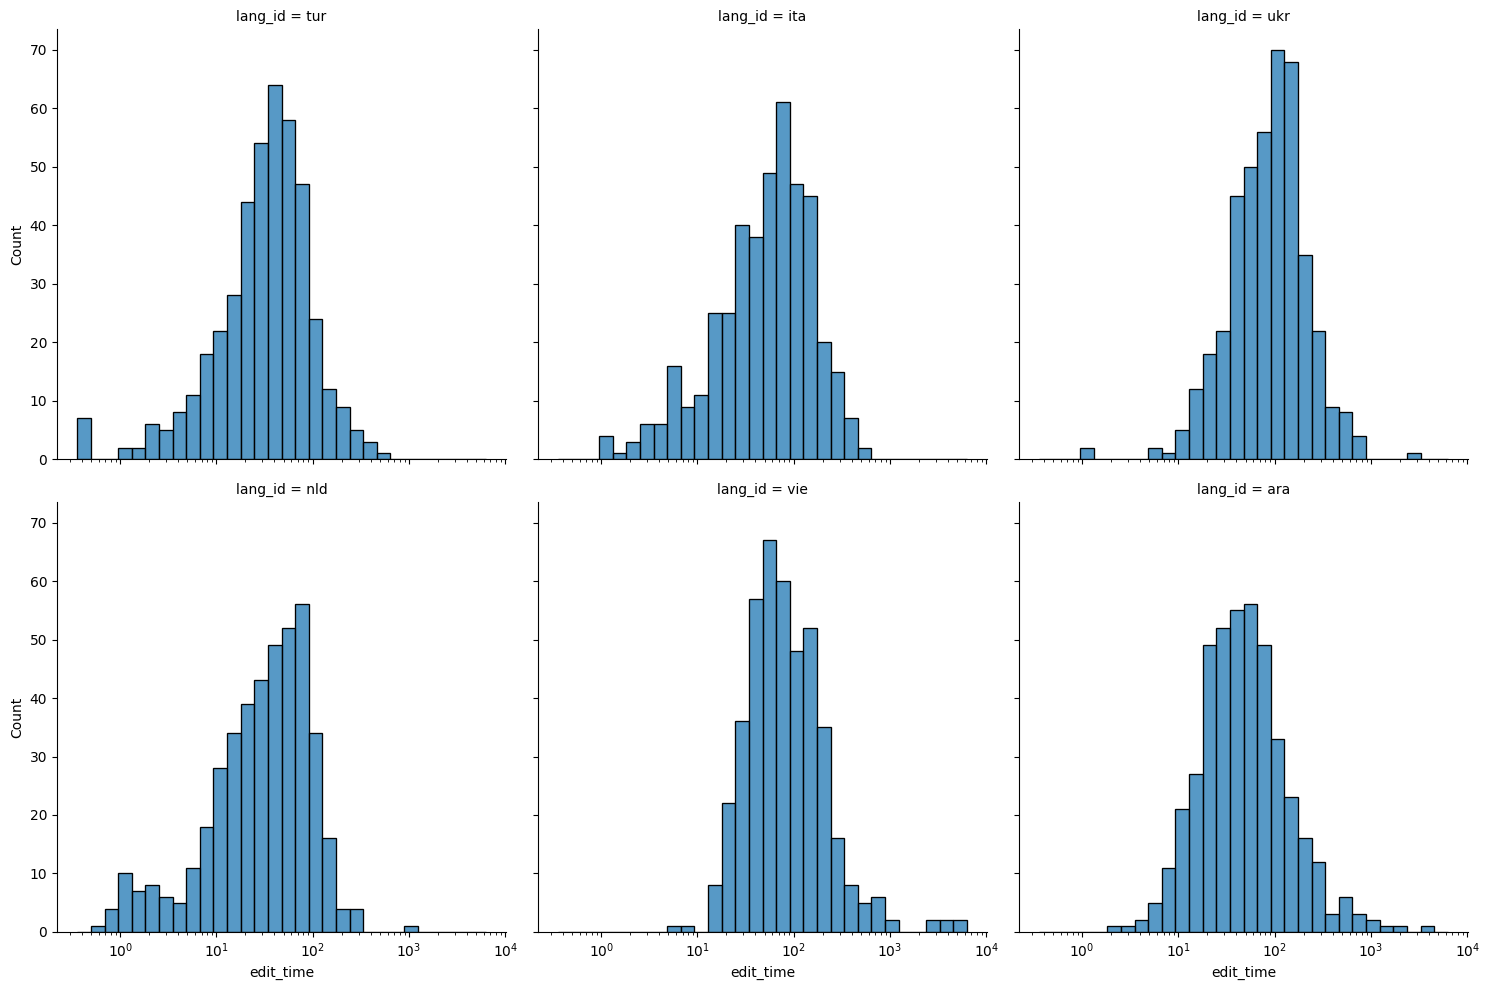

In [121]:
sns.displot(data=google, x='edit_time', col='lang_id', col_wrap=3,
            bins=30, log_scale=True)

In [128]:
ita_df_google= google[google['lang_id']=='ita']
ita_df_google['cometkiwi_qe'].describe()

count    430.000000
mean       0.870441
std        0.040668
min        0.675312
25%        0.867963
50%        0.884690
75%        0.893973
max        0.907780
Name: cometkiwi_qe, dtype: float64

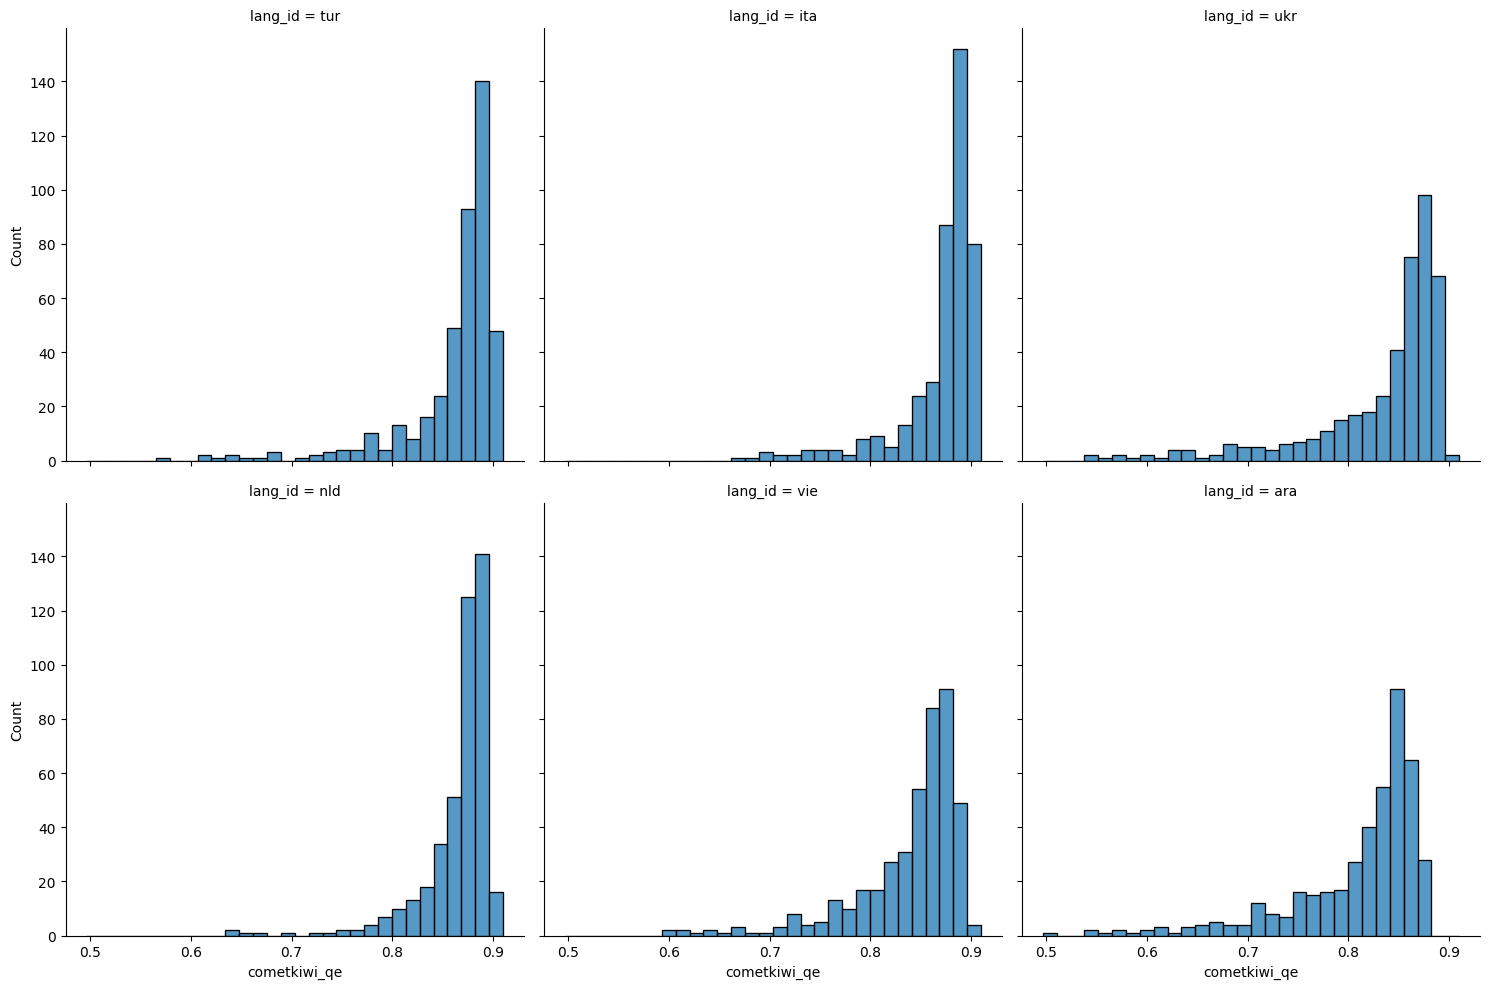

In [139]:
sns.displot(data=google, x='cometkiwi_qe', col='lang_id', col_wrap=3,
            bins=30)

In [137]:
more_than_95_ita['cometkiwi_qe'].describe()

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: cometkiwi_qe, dtype: float64